# Assignment 4: Deep Learning (MLP) vs Classical Machine Learning
**Course:** AI in Cyber Security Lab (`ENSP355`)  
**Student:** Yatharth Chopra (`2301420022`) | **Program:** B.Tech CSE (Data Science), Sem 7  
**University:** K.R. Mangalam University | **Faculty:** Monika Khatkar

---

### Objective
1. Train a **Multi-Layer Perceptron (`MLPClassifier`, 32 -> 16 ReLU, Adam, early stopping)** on the exact same preprocessed split as Assignment 3.
2. Compare **Logistic Regression, Decision Tree, Random Forest, and Neural Network (MLP)** across Accuracy, Precision, Recall, F1, **ROC-AUC**, unseen-profile generalisation, training time, and prediction latency.
3. Validate stability over **5 stratified random splits** (`mean +/- std`) and verify merge/feature-subset sensitivity.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from common import OUT_DIR, RANDOM_STATE, load_data
from preprocessing import build_preprocessor, split_data
from evaluation import fit_and_score

COLORS = ["#2a7ab0", "#7fb069", "#f4a261", "#d1495b"]
df = load_data()
X_train, X_test, y_train, y_test = split_data(df)

### 4.1 Single-Split Comparison & ROC Curves

In [2]:
def make_models(seed):
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=seed),
        "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=seed),
        "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=12, random_state=seed, n_jobs=-1),
        "Neural Network (MLP)": MLPClassifier(
            hidden_layer_sizes=(32, 16), activation="relu", solver="adam",
            max_iter=300, early_stopping=True, random_state=seed,
        ),
    }

rows, fitted_pipes, mlp_pipe = [], {}, None
for name, clf in make_models(RANDOM_STATE).items():
    pipe = Pipeline([("prep", build_preprocessor()), ("clf", clf)])
    res, _ = fit_and_score(pipe, X_train, X_test, y_train, y_test)
    rows.append({"model": name, **res})
    fitted_pipes[name] = pipe
    if name.startswith("Neural"):
        mlp_pipe = pipe

cmp_df = pd.DataFrame(rows).round(4)
display(cmp_df)

,model,accuracy,precision,recall,f1,roc_auc,train_time_s,predict_time_ms,acc_seen_profiles,acc_unseen_profiles,share_unseen_profiles
0,Logistic Regression,0.8985,0.9030,0.8729,0.8877,0.9643,0.0219,4.4013,0.9076,0.7213,0.0492
1,Decision Tree,0.9053,0.9074,0.8843,0.8957,0.9705,0.0197,4.3628,0.9089,0.8361,0.0492
2,Random Forest,0.9255,0.9322,0.9036,0.9177,0.9797,0.2969,41.8083,0.9292,0.8525,0.0492
3,Neural Network (MLP),0.9247,0.9274,0.9071,0.9171,0.9762,0.4671,4.3321,0.9275,0.8689,0.0492


C:\Users\yatha\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
C:\Users\yatha\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
C:\Users\yatha\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
C:\Users\yatha\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warning

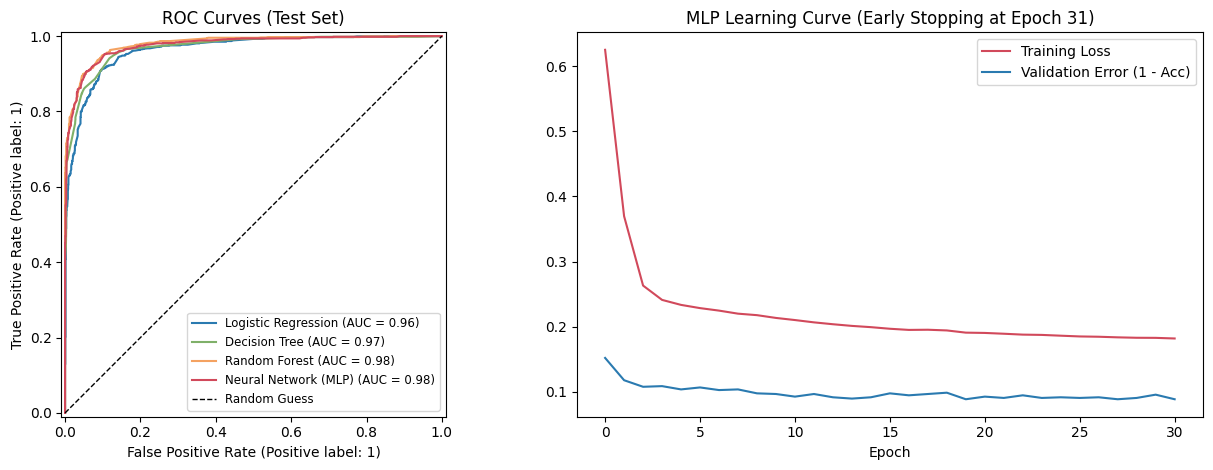

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for (name, pipe), color in zip(fitted_pipes.items(), COLORS):
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=axes[0], color=color)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random Guess")
axes[0].set_title("ROC Curves (Test Set)")
axes[0].legend(loc="lower right", fontsize=8.5)

mlp = mlp_pipe.named_steps["clf"]
axes[1].plot(mlp.loss_curve_, label="Training Loss", color="#d1495b")
axes[1].plot(1 - np.array(mlp.validation_scores_), label="Validation Error (1 - Acc)", color="#2a7ab0")
axes[1].set_xlabel("Epoch")
axes[1].set_title(f"MLP Learning Curve (Early Stopping at Epoch {mlp.n_iter_})")
axes[1].legend()
plt.tight_layout()
plt.show()

### 4.2 Repeated 5-Split Stability & Merge Validation

In [4]:
rep = pd.read_csv(OUT_DIR / "model_comparison_repeated.csv", index_col=0)
print("5-Split Repeated Evaluation (Mean +/- Std):")
display(rep.round(4))

cross = pd.read_csv(OUT_DIR / "cross_source_check.csv")
print("\nCross-Source Transfer Check (Naive vs Harmonised):")
display(cross.round(4))

5-Split Repeated Evaluation (Mean +/- Std):


,accuracy_mean,accuracy_std,f1_mean,f1_std,recall_mean,recall_std,roc_auc_mean,roc_auc_std,acc_unseen_profiles_mean,acc_unseen_profiles_std,train_time_s_mean,train_time_s_std
model,,,,,,,,,,,,
Logistic Regression,0.9001,0.0021,0.8893,0.0027,0.8729,0.0069,0.9619,0.0027,0.7363,0.0567,0.0192,0.0005
Decision Tree,0.9060,0.0052,0.8968,0.0062,0.8883,0.0115,0.9695,0.0019,0.8141,0.0387,0.0190,0.0008
Random Forest,0.9242,0.0027,0.9161,0.0032,0.9008,0.0059,0.9785,0.0016,0.8648,0.0306,0.2852,0.0099
Neural Network (MLP),0.9178,0.0059,0.9104,0.0060,0.9076,0.0083,0.9748,0.0024,0.8326,0.0388,0.5131,0.0626



Cross-Source Transfer Check (Naive vs Harmonised):


,model,direction,variant,accuracy,f1
0,Logistic Regression,A -> B,naive,0.3548,0.4215
1,Logistic Regression,A -> B,harmonised,0.6792,0.7341
2,Logistic Regression,B -> A,naive,0.2880,0.3610
3,Logistic Regression,B -> A,harmonised,0.6712,0.6855
4,Decision Tree,A -> B,naive,0.3607,0.4584
5,Decision Tree,A -> B,harmonised,0.6704,0.7489
6,Decision Tree,B -> A,naive,0.4479,0.5669
7,Decision Tree,B -> A,harmonised,0.6302,0.6332
